# Báo cáo accuracy phát hiện câu hỏi không trả lời được trên tập test

Notebook này tính **accuracy riêng cho tác vụ phát hiện câu hỏi không trả lời được** trên tập test của UIT-ViQuAD 2.0.

## Định nghĩa

Với mỗi mẫu test, mô hình QA trích xuất phải quyết định:
- **Có đáp án** (`is_impossible = False`): trả về một đoạn văn bản nằm trong context.
- **Không có đáp án** (`is_impossible = True`): trả về chuỗi rỗng.

Accuracy phát hiện câu hỏi không trả lời được đo mức khớp giữa nhãn `is_impossible` thật và dự đoán nhị phân từ mô hình (có trả về đáp án hay không). Chỉ số này **khác** với EM/F1 trích xuất đáp án — nó đo khả năng quyết định có/không có đáp án.

## Lưu ý quan trọng về nhãn test

UIT-ViQuAD 2.0 thường công bố test split ở dạng chỉ có context/câu hỏi; đáp án chuẩn (`answers.text`) và có khi cả nhãn `is_impossible` bị ẩn để chấm qua server. Trong dự án này, EDA đã ghi nhận `processed_test` thiếu nhãn chuẩn (7.301 mẫu). Vì vậy notebook này sẽ:
1. **Kiểm tra trước** xem test có đủ hai lớp `is_impossible` hay không.
2. Chỉ tính accuracy khi có đủ hai lớp.
3. Nếu không, báo rõ và đề xuất phương án thay thế (dùng validation làm proxy, hoặc báo cáo tỷ lệ dự đoán không trả lời được).

## Yêu cầu đầu vào

- `data/processed/testing.json` (7.301 mẫu, mỗi dòng một JSON).
- File dự đoán test đã sinh từ mô hình. Notebook tự dò các file trong `reports/`, `results/test_evaluation/` và các vị trí dự đoán phổ biến.

Định dạng dự đoán kỳ vọng: JSON list, mỗi phần tử có `id` (hoặc `example_id`) và `prediction_text` (hoặc `prediction`/`answer`). Chuỗi rỗng hoặc `null` nghĩa là mô hình dự đoán **không trả lời được**.

## Bước 1: Nạp tập test và kiểm tra nhãn

In [1]:
import json
from collections import Counter
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

test_path = project_root / "data" / "processed" / "testing.json"
assert test_path.exists(), f"Không tìm thấy {test_path}"

test_samples = []
with test_path.open("r", encoding="utf-8") as f:
    for line in f:
        test_samples.append(json.loads(line))

print(f"Số mẫu test: {len(test_samples)}")

# Phân bố nhãn is_impossible thực tế đọc được
label_counter = Counter(s.get("is_impossible") for s in test_samples)
print(f"Phân bố is_impossible: {dict(label_counter)}")

# Kiểm tra có đủ hai lớp không (điều kiện cần để accuracy có ý nghĩa)
has_true_class = label_counter.get(True, 0) > 0
has_false_class = label_counter.get(False, 0) > 0
has_both_classes = has_true_class and has_false_class

print(f"Có lớp unanswerable (True): {has_true_class}")
print(f"Có lớp answerable  (False): {has_false_class}")
if has_both_classes:
    print("Test đủ hai lớp, có thể tính accuracy phát hiện câu hỏi không trả lời.")
else:
    print("Test KHÔNG đủ hai lớp is_impossible.")

Số mẫu test: 7301
Phân bố is_impossible: {True: 1090, False: 6211}
Có lớp unanswerable (True): True
Có lớp answerable  (False): True
Test đủ hai lớp, có thể tính accuracy phát hiện câu hỏi không trả lời.


## Bước 2: Nạp dự đoán của mô hình

In [2]:
# Tìm file dự đoán test có sẵn trong dự án
candidate_prediction_paths = [
    project_root / "reports" / "predictions_test.json",
    project_root / "data" / "predictions" / "test_predictions.json",
    project_root / "predictions" / "test.json",
]
candidate_prediction_paths.append(project_root / "results" / "test_evaluation" / "xlm-roberta" / "seed-42" / "predictions.json")
candidate_prediction_paths += sorted((project_root / "results" / "test_evaluation").rglob("predictions.json"))

predictions_path = next((p for p in candidate_prediction_paths if p.exists()), None)
predictions = []
if predictions_path is None:
    print("⚠ Không tìm thấy file dự đoán test trong các vị trí đã hỗ trợ.")
    print("  Bước đối chiếu sẽ bỏ qua vì chưa có dự đoán.")
else:
    print(f"Đang đọc dự đoán: {predictions_path}")
    with predictions_path.open("r", encoding="utf-8") as f:
        predictions = json.load(f)
    if isinstance(predictions, dict):
        predictions = predictions.get("predictions", predictions)
    if not isinstance(predictions, list):
        raise TypeError("File dự đoán phải chứa JSON list hoặc key 'predictions' là JSON list.")
    print(f"Số dự đoán: {len(predictions)}")
    if predictions:
        print(f"Ví dụ phần tử đầu: {predictions[0]}")

# Chuẩn hóa về dict: id -> predicted_unanswerable (bool)
predicted_unanswerable_by_id = {}
for pred in predictions:
    pred_id = pred.get("id") or pred.get("example_id")
    pred_id = str(pred_id) if pred_id is not None else None
    if pred_id is None:
        continue

    # Ưu tiên cờ is_unanswerable nếu mô hình đã xuất trực tiếp
    if "is_unanswerable" in pred:
        value = pred["is_unanswerable"]
        if isinstance(value, str):
            value = value.strip().lower() in {"true", "1", "yes", "unanswerable"}
        predicted_unanswerable_by_id[pred_id] = bool(value)
        continue

    # Ngược lại: đáp án rỗng => không trả lời được
    if "prediction_text" in pred:
        pred_text = pred["prediction_text"]
    elif "prediction" in pred:
        pred_text = pred["prediction"]
    elif "answer" in pred:
        pred_text = pred["answer"]
    else:
        pred_text = ""
    predicted_unanswerable_by_id[pred_id] = (pred_text is None) or (str(pred_text).strip() == "")

print(f"Đã chuẩn hóa {len(predicted_unanswerable_by_id)} dự đoán")

Đang đọc dự đoán: d:\Môn năm 3\uit-viquad2-extractive-qa\Vietnamese_Extractive_Question_Answering_on_UIT_ViQuAD_2.0_Project\results\test_evaluation\xlm-roberta\seed-42\predictions.json
Số dự đoán: 7301
Ví dụ phần tử đầu: {'id': '0001-0001-0001', 'prediction_text': 'Thái Bình Dương, Oregon, Nevada, Arizona và tiểu bang Baja California của México', 'reference_texts': None, 'is_impossible': None}
Đã chuẩn hóa 7301 dự đoán


## Bước 3: Đối chiếu nhãn và tính accuracy

Chỉ mẫu có cả nhãn thật (`is_impossible` là True/False) và dự đoán mới được đưa vào tính. Positive class ở đây là `is_impossible = True` (câu **không** trả lời được).

In [3]:
y_true = []  # True = câu không có đáp án (positive class)
y_pred = []
missing_predictions = 0
invalid_labels = 0

for sample in test_samples:
    sample_id = sample.get("id")
    sample_id = str(sample_id) if sample_id is not None else None
    label = sample.get("is_impossible")

    if not isinstance(label, bool):
        invalid_labels += 1
        continue
    if sample_id not in predicted_unanswerable_by_id:
        missing_predictions += 1
        continue

    y_true.append(label)
    y_pred.append(predicted_unanswerable_by_id[sample_id])

print(f"Số mẫu được đánh giá: {len(y_true)}")
print(f"Số mẫu thiếu dự đoán: {missing_predictions}")
print(f"Số mẫu có nhãn không hợp lệ: {invalid_labels}")

# Các biến metric để Bước 4 dùng lại
accuracy = precision = recall = f1 = None
tn = fp = fn = tp = None

if y_true and has_both_classes:
    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        confusion_matrix,
    )

    accuracy = float(accuracy_score(y_true, y_pred))
    precision = float(precision_score(y_true, y_pred, pos_label=True, zero_division=0))
    recall = float(recall_score(y_true, y_pred, pos_label=True, zero_division=0))
    f1 = float(f1_score(y_true, y_pred, pos_label=True, zero_division=0))

    tn, fp, fn, tp = (int(value) for value in confusion_matrix(y_true, y_pred, labels=[False, True]).ravel())

    print()
    print("=== KẾT QUẢ PHÁT HIỆN CÂU HỎI KHÔNG TRẢ LỜI ĐƯỢC ===")
    print(f"Accuracy tổng:             {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Precision (unanswerable):  {precision:.4f}")
    print(f"Recall    (unanswerable):  {recall:.4f}")
    print(f"F1        (unanswerable):  {f1:.4f}")
    print()
    print("Confusion matrix (hàng=thật, cột=dự đoán):")
    print("                    dự đoán có ĐA     dự đoán không ĐA")
    print(f"thật có ĐA            {tn:8d}            {fp:8d}")
    print(f"thật không ĐA         {fn:8d}            {tp:8d}")
else:
    print("Không tính metric vì test hoặc dữ liệu đối chiếu không đủ hai lớp nhãn.")

Số mẫu được đánh giá: 7301
Số mẫu thiếu dự đoán: 0
Số mẫu có nhãn không hợp lệ: 0

=== KẾT QUẢ PHÁT HIỆN CÂU HỎI KHÔNG TRẢ LỜI ĐƯỢC ===
Accuracy tổng:             0.6917 (69.17%)
Precision (unanswerable):  0.1662
Recall    (unanswerable):  0.2651
F1        (unanswerable):  0.2043

Confusion matrix (hàng=thật, cột=dự đoán):
                    dự đoán có ĐA     dự đoán không ĐA
thật có ĐA                4761                1450
thật không ĐA              801                 289


## Bước 4: Confusion matrix trực quan

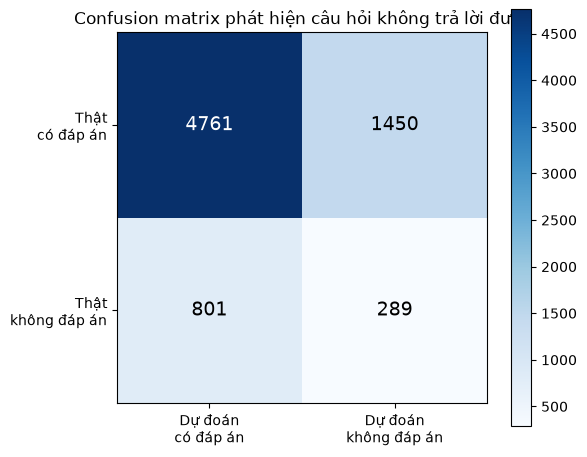

Đã lưu ảnh: d:\Môn năm 3\uit-viquad2-extractive-qa\Vietnamese_Extractive_Question_Answering_on_UIT_ViQuAD_2.0_Project\reports\images\unanswerable_detection_confusion_matrix.png


In [4]:
if y_true and has_both_classes and tn is not None:
    import matplotlib.pyplot as plt
    import numpy as np

    cm = np.array([[tn, fp], [fn, tp]], dtype=int)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Dự đoán\ncó đáp án", "Dự đoán\nkhông đáp án"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Thật\ncó đáp án", "Thật\nkhông đáp án"])
    ax.set_title("Confusion matrix phát hiện câu hỏi không trả lời được")

    threshold = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > threshold else "black",
                    fontsize=14)

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    images_dir = project_root / "reports" / "images"
    images_dir.mkdir(parents=True, exist_ok=True)
    out_img = images_dir / "unanswerable_detection_confusion_matrix.png"
    plt.savefig(out_img, dpi=120)
    plt.show()
    print(f"Đã lưu ảnh: {out_img}")

## Bước 5: Lưu báo cáo JSON

In [ ]:
report = {
    "predictions_path": str(predictions_path) if predictions_path is not None else None,
    "test_samples": len(test_samples),
    "evaluated_samples": len(y_true),
    "missing_predictions": missing_predictions,
    "invalid_labels": invalid_labels,
    "has_both_classes": has_both_classes,
    "accuracy": accuracy,
    "precision_unanswerable": precision,
    "recall_unanswerable": recall,
    "f1_unanswerable": f1,
    "confusion_matrix": {
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    },
}

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
report_path = reports_dir / "unanswerable_detection_report.json"
with report_path.open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print(f"Đã lưu báo cáo: {report_path}")